#데이터 전처리

In [ ]:
# 사진 파일 불러오기
!unzip Dormitory_64.zip

In [ ]:
# 사진파일 이름 1~64.(확장자) 형태로 변환
import os

base_dir = "dormitory"
houses = ["gryffindor", "hufflepuff", "ravenclaw", "slytherin"]

for house in houses:
    folder = os.path.join(base_dir, house)
    files = sorted(os.listdir(folder))
    for i, filename in enumerate(files, 1):
        # 원본 파일의 확장자 추출
        ext = os.path.splitext(filename)[1]
        new_name = f"{i}{ext}"
        src = os.path.join(folder, filename)
        dst = os.path.join(folder, new_name)
        os.rename(src, dst)
print("이름 변경 완료!")


In [ ]:
# webp 파일을 jpg로 변환
from PIL import Image
import os

def convert_webp_to_jpg(root_dir):
    for subdir, dirs, files in os.walk(root_dir):
        for file in files:
            if file.lower().endswith('.webp'):
                webp_path = os.path.join(subdir, file)
                jpg_path = os.path.splitext(webp_path)[0] + '.jpg'

                try:
                    img = Image.open(webp_path).convert('RGB')
                    img.save(jpg_path, 'JPEG', quality=95)  #quality 설정
                    os.remove(webp_path)
                    print(f'변환 완료: {webp_path} → {jpg_path}')
                except Exception as e:
                    print(f'변환 실패: {webp_path}, 에러: {e}')

# 실행
convert_webp_to_jpg('./dormitory')


#CNN

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
!unzip '/content/drive/MyDrive/2025 학교/DL/프로젝트/Dormitory_jpg.zip'

Archive:  /content/drive/MyDrive/2025 학교/DL/프로젝트/Dormitory_jpg.zip
   creating: dormitory/
   creating: dormitory/gryffindor/
  inflating: dormitory/gryffindor/1.jpg  
  inflating: dormitory/gryffindor/10.jpg  
  inflating: dormitory/gryffindor/11.jpg  
  inflating: dormitory/gryffindor/12.png  
  inflating: dormitory/gryffindor/13.jpg  
  inflating: dormitory/gryffindor/14.jpg  
  inflating: dormitory/gryffindor/15.jpg  
  inflating: dormitory/gryffindor/16.jpg  
  inflating: dormitory/gryffindor/17.jpg  
  inflating: dormitory/gryffindor/18.jpg  
  inflating: dormitory/gryffindor/19.jpg  
  inflating: dormitory/gryffindor/2.jpg  
  inflating: dormitory/gryffindor/20.jpg  
  inflating: dormitory/gryffindor/21.jpg  
  inflating: dormitory/gryffindor/22.jpg  
  inflating: dormitory/gryffindor/23.jpg  
  inflating: dormitory/gryffindor/24.jpg  
  inflating: dormitory/gryffindor/25.jpg  
  inflating: dormitory/gryffindor/26.jpg  
  inflating: dormitory/gryffindor/27.jpg  
  inflat

In [2]:
import os

# 폴더 구조 확인 코드
print("현재 폴더 구조:")
print(os.listdir('./dormitory'))

#폴더 하나 당 64개의 이미지

현재 폴더 구조:
['hufflepuff', 'ravenclaw', 'gryffindor', 'slytherin']


In [34]:
import pandas as pd
import numpy as np
import os
import shutil
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 확장자 설정
ImageDataGenerator.white_list_formats = ('png', 'jpg', 'jpeg', 'bmp', 'gif')

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    './dormitory',
    target_size=(256, 256),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    './dormitory',
    target_size=(256, 256),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)


Found 208 images belonging to 4 classes.
Found 48 images belonging to 4 classes.


In [48]:
# 모델 정의하기
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(256,256,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(16, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(4, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


In [37]:
# 기숙사 클래스 확인하기
print(train_generator.class_indices)
print(val_generator.class_indices)

{'gryffindor': 0, 'hufflepuff': 1, 'ravenclaw': 2, 'slytherin': 3}
{'gryffindor': 0, 'hufflepuff': 1, 'ravenclaw': 2, 'slytherin': 3}


In [50]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

history = model.fit(
    train_generator,
    epochs=50,
    validation_data=val_generator,
    callbacks=[early_stop]
)


Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 900ms/step - accuracy: 0.2957 - loss: 2.7940 - val_accuracy: 0.2500 - val_loss: 1.3879
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 576ms/step - accuracy: 0.2726 - loss: 1.3912 - val_accuracy: 0.2292 - val_loss: 1.3934
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 797ms/step - accuracy: 0.3253 - loss: 1.3928 - val_accuracy: 0.3125 - val_loss: 1.3981
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 583ms/step - accuracy: 0.2352 - loss: 1.3861 - val_accuracy: 0.3125 - val_loss: 1.3909
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 577ms/step - accuracy: 0.2628 - loss: 1.3756 - val_accuracy: 0.2917 - val_loss: 1.3946
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 793ms/step - accuracy: 0.3334 - loss: 1.3683 - val_accuracy: 0.3750 - val_loss: 1.3898
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 579ms/step - accuracy: 0.3229 - loss: 1.3861 - val_accuracy: 0.2292 - val_loss: 1.3850
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 575ms/step - accuracy: 0.3149 - loss: 1.3558 - val_accuracy: 0.2292 - val_loss

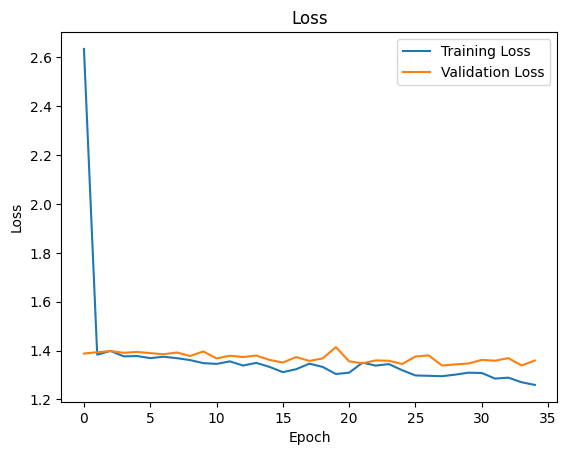

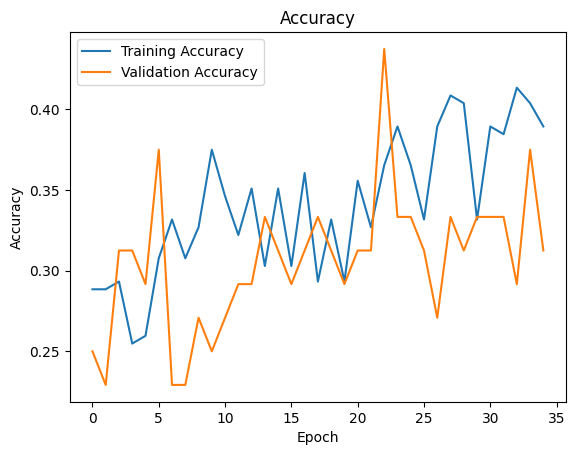

In [51]:
import matplotlib.pyplot as plt

# loss 그래프
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

# accuracy 그래프
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()


In [9]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab import files
import cv2
import numpy as np
import PIL.Image
import io

In [52]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
# 레이블 정보
labels = ['gryffindor', 'hufflepuff', 'ravenclaw', 'slytherin']


# OpenCV를 사용해서 이미지 읽어 들이기
im = cv2.imread('test_image_1.jpg')
im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)  #jpg 업로드 필요
im = cv2.resize(im, (256, 256))
plt.imshow(im) # 이미지 출력하기
plt.show()

In [53]:
res = model.predict( im.reshape(-1, 256,256,3) )
print("MM.... right. ", "Okay,", res.max()*100 ,"%", labels[res.argmax()], "!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step
MM.... right.  Okay, 79.8292 % gryffindor !


In [54]:
im = cv2.imread('test_image_2.jpg')
im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)  #jpg 업로드 필요
im = cv2.resize(im, (256, 256))
plt.imshow(im) # 이미지 출력하기
plt.show()

In [55]:
res = model.predict( im.reshape(-1, 256,256,3) )
print("MM.... right. ", "Okay,", res.max()*100 ,"%", labels[res.argmax()], "!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
MM.... right.  Okay, 98.109795 % ravenclaw !


In [17]:
# 브라우저에서 웹캠으로 사진 찍기
def take_photo(filename='picture.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = '사진 찍기';
            div.appendChild(capture);

            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});

            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            // 클릭할 때 사진 캡처
            await new Promise((resolve) => capture.onclick = resolve);

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getTracks().forEach(track => track.stop());
            div.remove();

            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = io.BytesIO(base64.b64decode(data.split(',')[1]))

    # 저장
    image = PIL.Image.open(binary)
    image.save(filename)
    print(f"{filename} 저장 완료!")

    return filename


In [58]:
# 필요한 모듈 import
import base64

# 사진 찍기 실행
take_photo()

In [59]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
# 레이블 정보
labels = ['gryffindor', 'hufflepuff', 'ravenclaw', 'slytherin']


# OpenCV를 사용해서 이미지 읽어 들이기
im = cv2.imread('picture.jpg')
im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)  #jpg 업로드 필요
im = cv2.resize(im, (256, 256))
plt.imshow(im) # 이미지 출력하기
plt.show()

In [60]:
res = model.predict( im.reshape(-1, 256,256,3) )
print("MM.... right. ", "Okay,", res.max()*100 ,"%", labels[res.argmax()], "!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
MM.... right.  Okay, 39.73116 % ravenclaw !
